# 7주차 실험을 단계별로 확인하기

이 노트북은 보정된 W0와 W1에서 Pin-All, Evict/Recompute, Fixed TTL을 비교합니다. 각 셀을 위에서부터 하나씩 실행하세요.

실제 LLM이나 GPU를 실행하지 않고 이산 사건 시뮬레이터를 사용합니다. prefill·decode 속도는 아직 자리표시자이므로 절대 성능보다 정책 간 상대 변화에 초점을 둡니다.

## 1. 실행 환경과 모듈 불러오기

In [32]:
import os, sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from kvbench.engine import Simulator
from kvbench.experiment import (
    WEEK7_CONDITIONS, WEEK7_POLICIES, WEEK7_SEEDS, run_week7
)
from kvbench.metrics import summarize
from kvbench.policies import make_policy
from kvbench.system import load_policy_params, load_system_config
from kvbench.workload import generate, load_config, validate

print('project root:', ROOT)
print('python:', sys.version.split()[0])

project root: /Users/ukksung/Desktop/private/성균관대학교 데사융 수업/4-1. 캡스톤프로젝트/code
python: 3.9.6


## 2. 5주차와 7주차의 차이

먼저 실제로 바꾼 파라미터와 실험 범위를 한 표로 비교합니다. 기존 5주차 설정 파일은 보존하고, 7주차 전용 설정 파일을 따로 사용합니다.

In [33]:
smoke = load_config('configs/smoke.json')
week7 = load_config('configs/week7.json')
system = load_system_config('configs/system_1080ti_llama3b.json')
policy_params = {
    name: load_policy_params('configs/policies_week7.json', name)
    for name in WEEK7_POLICIES
}
week5_ttl = load_policy_params('configs/policies.json', 'fixed_ttl')['ttl_ms']
week7_ttl = load_policy_params('configs/policies_week7.json', 'fixed_ttl')['ttl_ms']

week_changes = pd.DataFrame([
    {
        '항목': 'stress 세션 도착률',
        '5주차': f'{smoke.stress_arrival_rate_per_s:.1f} sessions/s',
        '7주차': f'{week7.stress_arrival_rate_per_s:.1f} sessions/s',
        '의도': 'W0가 시작부터 포화되는 문제 보정',
    },
    {
        '항목': '60초 동안 예상 stress 세션',
        '5주차': f'약 {smoke.stress_arrival_rate_per_s * smoke.duration_ms / 1000:.0f}개',
        '7주차': f'약 {week7.stress_arrival_rate_per_s * week7.duration_ms / 1000:.0f}개',
        '의도': '정책 차이를 볼 수 있는 비포화 기준점 확보',
    },
    {
        '항목': 'Fixed TTL',
        '5주차': f'{week5_ttl / 1000:.0f}초 (실험에서 제외)',
        '7주차': f'{week7_ttl / 1000:.0f}초',
        '의도': '1~5초 도구 대기 중 실제 만료가 발생하도록 조정',
    },
    {
        '항목': '비교 정책',
        '5주차': 'Pin-All, Evict/Recompute',
        '7주차': 'Pin-All, Evict/Recompute, Fixed TTL',
        '의도': '두 극단 사이의 TTL 정책 추가',
    },
    {
        '항목': '도구 대기 조건',
        '5주차': 'W0 1배',
        '7주차': 'W0 1배, W1 2배·4배',
        '의도': '지속 점유 압력이 커질 때 정책 비교',
    },
    {
        '항목': 'seed',
        '5주차': '0~4',
        '7주차': '0~4',
        '의도': '동일하게 유지',
    },
])
display(week_changes)

unchanged = pd.DataFrame({
    '변경하지 않은 항목': [
        '실험 생성 시간', 'warm-up', '일반 요청 도착률', '기본 도구 대기시간',
        '입력·출력 토큰 범위', '시스템 파라미터'
    ],
    '값': [
        '60초', '10초', '2.0 requests/s', '1~5초',
        '5주차와 동일', '5주차와 동일'
    ],
})
display(unchanged)


,항목,5주차,7주차,의도
0,stress 세션 도착률,0.5 sessions/s,0.2 sessions/s,W0가 시작부터 포화되는 문제 보정
1,60초 동안 예상 stress 세션,약 30개,약 12개,정책 차이를 볼 수 있는 비포화 기준점 확보
2,Fixed TTL,30초 (실험에서 제외),3초,1~5초 도구 대기 중 실제 만료가 발생하도록 조정
3,비교 정책,"Pin-All, Evict/Recompute","Pin-All, Evict/Recompute, Fixed TTL",두 극단 사이의 TTL 정책 추가
4,도구 대기 조건,W0 1배,"W0 1배, W1 2배·4배",지속 점유 압력이 커질 때 정책 비교
5,seed,0~4,0~4,동일하게 유지


,변경하지 않은 항목,값
0,실험 생성 시간,60초
1,warm-up,10초
2,일반 요청 도착률,2.0 requests/s
3,기본 도구 대기시간,1~5초
4,입력·출력 토큰 범위,5주차와 동일
5,시스템 파라미터,5주차와 동일


### W0 보정 전후 결과

Pin-All 정책과 seed 5개를 동일하게 두고, `stress_arrival_rate_per_s`만 다른 두 설정을 실행합니다. 따라서 아래 차이는 주로 stress 세션 도착률을 0.5에서 0.2로 낮춘 효과입니다.

normal_p95_ttft_ms           normal_reject_rate_pct       \
                   mean       std                   mean  std   
week                                                            
5주차            23944.48  13116.36                   12.6  6.8   
7주차              258.78     68.22                    0.0  0.0   

     peak_kv_occupancy_pct        
                      mean   std  
week                              
5주차                  99.97  0.04  
7주차                  66.29  8.39

해석: 5주차 W0는 이미 포화됐지만, 7주차 W0는 거절 없이 약 66% 점유율에서 동작합니다.
따라서 7주차에서는 2배·4배 도구 대기를 적용했을 때의 정책 차이를 관찰할 여유가 생겼습니다.


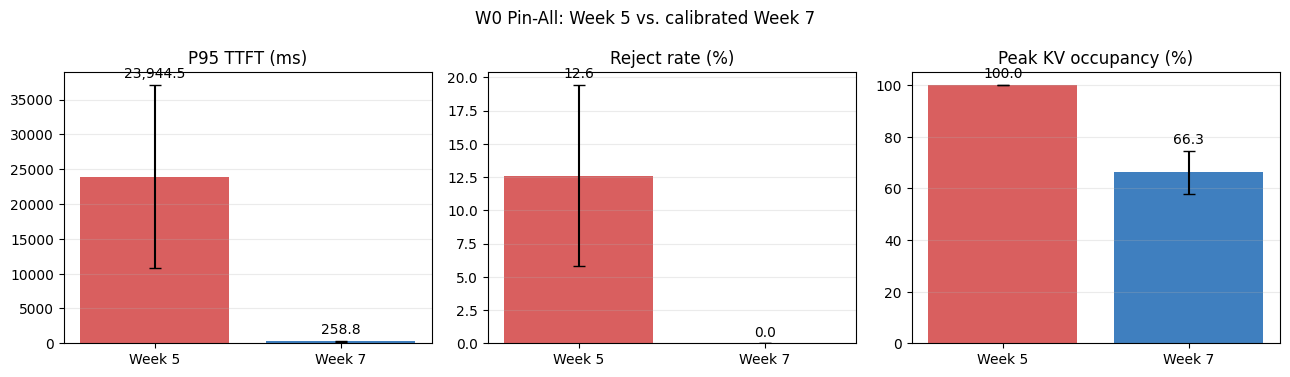

In [34]:
week_result_rows = []
for week_label, config in [('5주차', smoke), ('7주차', week7)]:
    for seed in WEEK7_SEEDS:
        rows = generate(config, 'W0', 1, seed)
        sim = Simulator(rows, system, make_policy('pin_all', {})).run()
        week_result_rows.append({
            'week': week_label,
            'seed': seed,
            **summarize(sim, config.warmup_ms),
        })

week_results = pd.DataFrame(week_result_rows)
metrics = [
    'normal_p95_ttft_ms',
    'normal_reject_rate_pct',
    'peak_kv_occupancy_pct',
]
week_summary = week_results.groupby('week')[metrics].agg(['mean', 'std']).loc[['5주차', '7주차']]
display(week_summary.round(2))

plot_specs = [
    ('normal_p95_ttft_ms', 'P95 TTFT (ms)'),
    ('normal_reject_rate_pct', 'Reject rate (%)'),
    ('peak_kv_occupancy_pct', 'Peak KV occupancy (%)'),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
colors = ['#d95f5f', '#3f7fbf']
for ax, (metric, title) in zip(axes, plot_specs):
    means = week_results.groupby('week')[metric].mean().loc[['5주차', '7주차']]
    stds = week_results.groupby('week')[metric].std().loc[['5주차', '7주차']]
    bars = ax.bar(['Week 5', 'Week 7'], means.values, yerr=stds.values, capsize=4, color=colors)
    ax.bar_label(bars, labels=[f'{value:,.1f}' for value in means.values], padding=3)
    ax.set_title(title)
    ax.grid(axis='y', alpha=.25)
plt.suptitle('W0 Pin-All: Week 5 vs. calibrated Week 7')
plt.tight_layout()

print('해석: 5주차 W0는 이미 포화됐지만, 7주차 W0는 거절 없이 약 66% 점유율에서 동작합니다.')
print('따라서 7주차에서는 2배·4배 도구 대기를 적용했을 때의 정책 차이를 관찰할 여유가 생겼습니다.')


## 3. 전체 실험 설계

W1 1배는 현재 생성기에서 W0와 라벨 외 입력이 같으므로 중복을 제외합니다. 최종 실험은 W0 1배, W1 2배, W1 4배입니다.

In [35]:
design = pd.DataFrame(WEEK7_CONDITIONS, columns=['load', 'workload', 'stress_level'])
display(design)
print('policies:', WEEK7_POLICIES)
print('seeds:', WEEK7_SEEDS)
print('total runs:', len(WEEK7_CONDITIONS) * len(WEEK7_POLICIES) * len(WEEK7_SEEDS))

,load,workload,stress_level
0,1x,W0,1
1,2x,W1,2
2,4x,W1,4


policies: ('pin_all', 'evict_recompute', 'fixed_ttl')
seeds: (0, 1, 2, 3, 4)
total runs: 45


## 4. W0 트레이스 한 개 생성하고 검사

먼저 파일을 만들지 않고 seed 0 트레이스를 메모리에서 생성합니다. `normal`은 한 턴 요청이고 `stress`는 도구를 사용하는 다중 턴 세션입니다.

In [36]:
w0_rows = generate(week7, 'W0', 1, seed=0)
trace_summary = validate(w0_rows)
trace_df = pd.DataFrame(asdict(row) for row in w0_rows)

display(pd.Series(trace_summary, name='W0 seed 0'))
display(trace_df.head())
print('first arrival:', trace_df.session_arrival_ms.min(), 'ms')
print('last external arrival:', trace_df.session_arrival_ms.max(), 'ms')

sessions           135
turns              172
normal_requests    123
stress_sessions     12
tool_calls          37
Name: W0 seed 0, dtype: int64

,schema_version,session_id,turn_id,request_id,request_class,seed,workload_id,stress_level,session_arrival_ms,arrival_ms,depends_on_request_id,prompt_tokens,output_tokens,context_tokens,expected_turns,tool_duration_ms,arrival_rate_per_s,burst_id
0,1,normal-000000,0,normal-000000:0,normal,0,W0,1,586.553935,586.553935,None,297,84,297,1,0.0,2.0,None
1,1,normal-000001,0,normal-000001:0,normal,0,W0,1,684.421112,684.421112,None,416,37,416,1,0.0,2.0,None
2,1,normal-000002,0,normal-000002:0,normal,0,W0,1,1561.263401,1561.263401,None,461,92,461,1,0.0,2.0,None
3,1,normal-000003,0,normal-000003:0,normal,0,W0,1,1903.790018,1903.790018,None,168,44,168,1,0.0,2.0,None
4,1,normal-000004,0,normal-000004:0,normal,0,W0,1,2769.352764,2769.352764,None,427,42,427,1,0.0,2.0,None


first arrival: 586.5539354065445 ms
last external arrival: 59841.262553607834 ms


## 5. stress 세션의 턴 연결과 누적 토큰 확인

In [37]:
stress_id = trace_df.loc[trace_df.request_class == 'stress', 'session_id'].iloc[0]
columns = [
    'session_id', 'turn_id', 'arrival_ms', 'depends_on_request_id',
    'prompt_tokens', 'context_tokens', 'output_tokens', 'tool_duration_ms'
]
display(trace_df.loc[trace_df.session_id == stress_id, columns])

,session_id,turn_id,arrival_ms,depends_on_request_id,prompt_tokens,context_tokens,output_tokens,tool_duration_ms
5,stress-000000,0,3212.013182,None,3907,3907,115,4906.0
6,stress-000000,1,NaN,stress-000000:0,139,4161,101,1561.0
7,stress-000000,2,NaN,stress-000000:1,196,4458,36,3066.0
8,stress-000000,3,NaN,stress-000000:2,193,4687,96,1911.0
9,stress-000000,4,NaN,stress-000000:3,248,5031,127,0.0


## 6. 도착 시각, 토큰 수, 도구 대기시간 분포 확인

count    37.000000
mean      3.146297
std       1.039612
min       1.406000
50%       3.112000
90%       4.464800
max       4.906000
Name: tool_duration_ms, dtype: float64

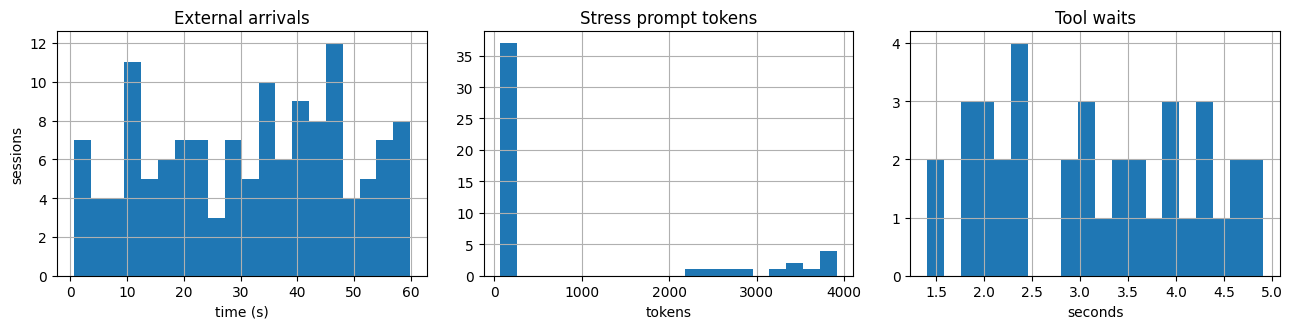

In [38]:
stress = trace_df[trace_df.request_class == 'stress']
wait_seconds = stress.loc[stress.tool_duration_ms > 0, 'tool_duration_ms'] / 1000

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
trace_df[trace_df.turn_id == 0].session_arrival_ms.div(1000).hist(bins=20, ax=axes[0])
axes[0].set(title='External arrivals', xlabel='time (s)', ylabel='sessions')
stress.prompt_tokens.hist(bins=20, ax=axes[1])
axes[1].set(title='Stress prompt tokens', xlabel='tokens')
wait_seconds.hist(bins=20, ax=axes[2])
axes[2].set(title='Tool waits', xlabel='seconds')
plt.tight_layout()
display(wait_seconds.describe(percentiles=[.5, .9]))

## 7. W0 seed 0을 Pin-All로 한 번 실행

시뮬레이터는 트레이스를 시간순으로 재생합니다. 실행이 끝나면 GPU·CPU 자원이 모두 반환돼야 합니다.

In [39]:
pin_sim = Simulator(w0_rows, system, make_policy('pin_all', policy_params['pin_all'])).run()
pin_summary = summarize(pin_sim, week7.warmup_ms)
display(pd.Series(pin_summary, name='W0 seed 0 / Pin-All'))
print('GPU blocks after run:', pin_sim.gpu.used_blocks)
print('CPU bytes after run:', pin_sim.cpu.used_bytes)

policy                            pin_all
sessions                              135
end_ms                           115738.4
normal_submitted                      108
normal_completed                      108
normal_rejected                         0
normal_p50_ttft_ms                 42.875
normal_p95_ttft_ms             194.064132
normal_reject_rate_pct                0.0
peak_kv_occupancy_pct               63.12
all_p95_ttft_ms                423.371221
completed_jobs                        117
rejected_jobs                           0
throughput_jobs_per_s              1.1065
task_completion_mean_ms       4191.565436
task_completion_p95_ms       22010.916667
eviction_count                          0
eviction_per_job                      0.0
offload_count                           0
reload_count                            0
transfer_bytes                          0
transfer_gib_per_job                  0.0
recomputed_tokens                       0
recomputed_tokens_per_job         

GPU blocks after run: 0
CPU bytes after run: 0


## 8. 같은 트레이스를 세 정책으로 비교

In [40]:
preview_rows = []
preview_sims = {}
for policy in WEEK7_POLICIES:
    sim = Simulator(w0_rows, system, make_policy(policy, policy_params[policy])).run()
    preview_sims[policy] = sim
    preview_rows.append({'policy': policy, **summarize(sim, week7.warmup_ms)})

preview = pd.DataFrame(preview_rows).set_index('policy')
display(preview[[
    'normal_p95_ttft_ms', 'normal_reject_rate_pct', 'peak_kv_occupancy_pct',
    'eviction_count', 'recomputed_tokens'
]])

,normal_p95_ttft_ms,normal_reject_rate_pct,peak_kv_occupancy_pct,eviction_count,recomputed_tokens
policy,,,,,
pin_all,194.064132,0.0,63.12,0,0
evict_recompute,530.736231,0.0,59.83,37,137478
fixed_ttl,454.927390,0.0,63.85,21,77305


## 9. Fixed TTL 1초·3초·5초 비교

같은 W0 seed 5개에서 TTL만 바꿉니다. 5초는 도구 대기 상한과 같아서 거의 만료되지 않고, 1초는 대부분을 삭제합니다.

In [41]:
ttl_records = []
for ttl_ms in (1000, 3000, 5000):
    for seed in WEEK7_SEEDS:
        rows = generate(week7, 'W0', 1, seed)
        policy = make_policy('fixed_ttl', {'ttl_ms': ttl_ms, 'evict_on_pressure': False})
        sim = Simulator(rows, system, policy).run()
        ttl_records.append({'ttl_ms': ttl_ms, 'seed': seed, **summarize(sim, week7.warmup_ms)})

ttl_df = pd.DataFrame(ttl_records)
ttl_metrics = [
    'normal_p95_ttft_ms', 'normal_reject_rate_pct', 'peak_kv_occupancy_pct',
    'eviction_count', 'recomputed_tokens'
]
ttl_table = ttl_df.groupby('ttl_ms')[ttl_metrics].agg(['mean', 'std']).round(2)
display(ttl_table)

normal_p95_ttft_ms         normal_reject_rate_pct       \
                     mean     std                   mean  std   
ttl_ms                                                          
1000               621.51  174.71                    0.0  0.0   
3000               437.26   80.13                    0.0  0.0   
5000               258.78   68.22                    0.0  0.0   

       peak_kv_occupancy_pct        eviction_count       recomputed_tokens  \
                        mean    std           mean   std              mean   
ttl_ms                                                                       
1000                   65.99  11.59           35.8  6.53          124720.2   
3000                   66.42   9.09           18.2  3.03           63749.6   
5000                   66.29   8.39            0.0  0.00               0.0   

                  
             std  
ttl_ms            
1000    22434.93  
3000    11896.30  
5000        0.00

## 10. W1에서 대기시간만 증가하는지 확인

같은 seed의 W0와 W1은 ID·토큰 구성이 같아야 합니다. W1 2배에서는 중간 턴의 도구 대기시간만 정확히 2배가 됩니다.

In [42]:
w1_rows = generate(week7, 'W1', 2, seed=0)
w0_by_id = {row.request_id: row for row in w0_rows}

for row in w1_rows:
    base = w0_by_id[row.request_id]
    assert row.prompt_tokens == base.prompt_tokens
    assert row.output_tokens == base.output_tokens
    assert row.context_tokens == base.context_tokens
    assert row.tool_duration_ms == base.tool_duration_ms * 2

sample = []
for row in w1_rows:
    if row.tool_duration_ms > 0:
        sample.append({
            'request_id': row.request_id,
            'W0_wait_ms': w0_by_id[row.request_id].tool_duration_ms,
            'W1_2x_wait_ms': row.tool_duration_ms,
        })
display(pd.DataFrame(sample).head())
print('input control: OK')

,request_id,W0_wait_ms,W1_2x_wait_ms
0,stress-000000:0,4906.0,9812.0
1,stress-000000:1,1561.0,3122.0
2,stress-000000:2,3066.0,6132.0
3,stress-000000:3,1911.0,3822.0
4,stress-000001:0,2455.0,4910.0


input control: OK


## 11. 45회 본 실험 실행

아래 셀은 트레이스 15개와 run 45개를 저장합니다. 지정한 폴더에 완성된 `summary.csv`와 `comparison.csv`가 있으면 기존 결과를 재사용하므로 같은 셀을 다시 실행해도 됩니다. 새로운 실험을 따로 실행하려면 `RUN_NAME`을 `week7_notebook_v2`처럼 바꾸세요.

In [43]:
RUN_NAME = 'week7_notebook_v1'
OUTPUT = Path(os.environ.get('KV_BENCH_OUTPUT', ROOT / 'results' / RUN_NAME))
raw_summary_path = OUTPUT / 'summary.csv'
comparison_path = OUTPUT / 'comparison.csv'

if raw_summary_path.exists() and comparison_path.exists():
    print('reuse completed experiment:', OUTPUT)
elif OUTPUT.exists():
    raise ValueError(
        f'incomplete output folder exists: {OUTPUT}\n'
        '기존 파일을 보존하기 위해 중단했습니다. RUN_NAME을 v2처럼 바꿔 다시 실행하세요.'
    )
else:
    raw_summary_path, comparison_path = run_week7(
        'configs/week7.json',
        'configs/system_1080ti_llama3b.json',
        'configs/policies_week7.json',
        OUTPUT,
        keep_events=True,
    )
    print('new experiment completed:', OUTPUT)

print('raw summary:', raw_summary_path)
print('comparison:', comparison_path)

reuse completed experiment: /Users/ukksung/Desktop/private/성균관대학교 데사융 수업/4-1. 캡스톤프로젝트/code/results/week7_notebook_v1
raw summary: /Users/ukksung/Desktop/private/성균관대학교 데사융 수업/4-1. 캡스톤프로젝트/code/results/week7_notebook_v1/summary.csv
comparison: /Users/ukksung/Desktop/private/성균관대학교 데사융 수업/4-1. 캡스톤프로젝트/code/results/week7_notebook_v1/comparison.csv


## 12. 평균·표준편차와 seed별 SLO 통과율 확인

In [44]:
comparison = pd.read_csv(comparison_path)
display(comparison)

presentation_columns = [
    'policy', 'load',
    'normal_p95_ttft_ms_mean', 'normal_p95_ttft_ms_std',
    'normal_reject_rate_pct_mean', 'peak_kv_occupancy_pct_mean',
    'all_slo_pass_rate_pct', 'all_seeds_pass',
]
display(comparison[presentation_columns].round(2))

,policy,load,seeds,normal_p95_ttft_ms_mean,normal_p95_ttft_ms_std,normal_reject_rate_pct_mean,normal_reject_rate_pct_std,peak_kv_occupancy_pct_mean,peak_kv_occupancy_pct_std,eviction_count_mean,eviction_count_std,recomputed_tokens_mean,recomputed_tokens_std,ttft_ratio_vs_policy_1x_mean,ttft_ratio_vs_policy_1x_std,ttft_slo_pass_rate_pct,reject_slo_pass_rate_pct,occupancy_slo_pass_rate_pct,all_slo_pass_rate_pct,all_seeds_pass
0,pin_all,1x,5,258.778046,68.221382,0.000000,0.000000,66.292,8.386091,0.0,0.000000,0.0,0.000000,1.000000,0.000000,100.0,100.0,100.0,100.0,True
1,pin_all,2x,5,260.265458,67.782260,0.000000,0.000000,85.250,10.798039,0.0,0.000000,0.0,0.000000,1.006204,0.013873,100.0,100.0,60.0,60.0,False
2,pin_all,4x,5,14229.298758,14790.639566,1.988464,3.949137,98.410,3.012756,0.0,0.000000,0.0,0.000000,61.333426,71.013748,40.0,100.0,0.0,0.0,False
3,evict_recompute,1x,5,629.487547,183.325701,0.000000,0.000000,63.582,13.339984,36.2,6.418723,126002.8,22266.767653,1.000000,0.000000,100.0,100.0,100.0,100.0,True
4,evict_recompute,2x,5,488.190383,81.561607,0.000000,0.000000,61.374,9.926693,36.2,6.418723,126002.8,22266.767653,0.805026,0.132324,100.0,100.0,100.0,100.0,True
5,evict_recompute,4x,5,467.673073,93.691479,0.000000,0.000000,54.606,8.808773,36.2,6.418723,126002.8,22266.767653,0.767698,0.142804,100.0,100.0,100.0,100.0,True
6,fixed_ttl,1x,5,437.262231,80.133161,0.000000,0.000000,66.420,9.093099,18.2,3.033150,63749.6,11896.304018,1.000000,0.000000,100.0,100.0,100.0,100.0,True
7,fixed_ttl,2x,5,442.241520,64.149105,0.000000,0.000000,78.770,12.753006,31.2,4.549725,108507.8,17637.912524,1.025677,0.145149,100.0,100.0,80.0,80.0,False
8,fixed_ttl,4x,5,467.673073,93.691479,0.000000,0.000000,72.428,8.630919,36.2,6.418723,126002.8,22266.767653,1.069042,0.116932,100.0,100.0,100.0,100.0,True


,policy,load,normal_p95_ttft_ms_mean,normal_p95_ttft_ms_std,normal_reject_rate_pct_mean,peak_kv_occupancy_pct_mean,all_slo_pass_rate_pct,all_seeds_pass
0,pin_all,1x,258.78,68.22,0.00,66.29,100.0,True
1,pin_all,2x,260.27,67.78,0.00,85.25,60.0,False
2,pin_all,4x,14229.30,14790.64,1.99,98.41,0.0,False
3,evict_recompute,1x,629.49,183.33,0.00,63.58,100.0,True
4,evict_recompute,2x,488.19,81.56,0.00,61.37,100.0,True
5,evict_recompute,4x,467.67,93.69,0.00,54.61,100.0,True
6,fixed_ttl,1x,437.26,80.13,0.00,66.42,100.0,True
7,fixed_ttl,2x,442.24,64.15,0.00,78.77,80.0,False
8,fixed_ttl,4x,467.67,93.69,0.00,72.43,100.0,True


## 13. 발표용 핵심 지표 그래프

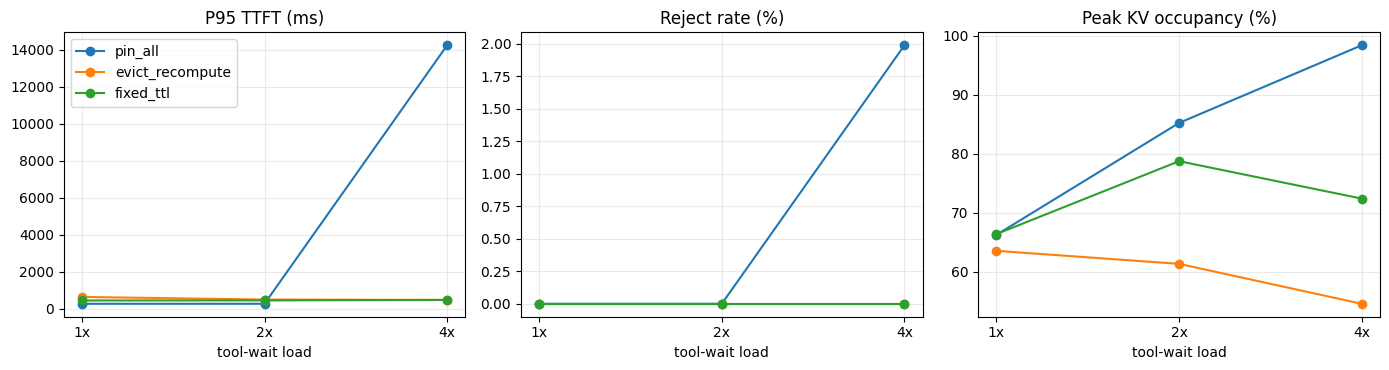

In [45]:
metrics = [
    ('normal_p95_ttft_ms_mean', 'P95 TTFT (ms)'),
    ('normal_reject_rate_pct_mean', 'Reject rate (%)'),
    ('peak_kv_occupancy_pct_mean', 'Peak KV occupancy (%)'),
]
load_order = ['1x', '2x', '4x']
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (metric, title) in zip(axes, metrics):
    for policy in WEEK7_POLICIES:
        part = comparison[comparison.policy == policy].set_index('load').loc[load_order]
        ax.plot(load_order, part[metric], marker='o', label=policy)
    ax.set(title=title, xlabel='tool-wait load')
    ax.grid(alpha=.25)
axes[0].legend()
plt.tight_layout()

## 14. 4배 부하의 대표 메모리 점유 곡선

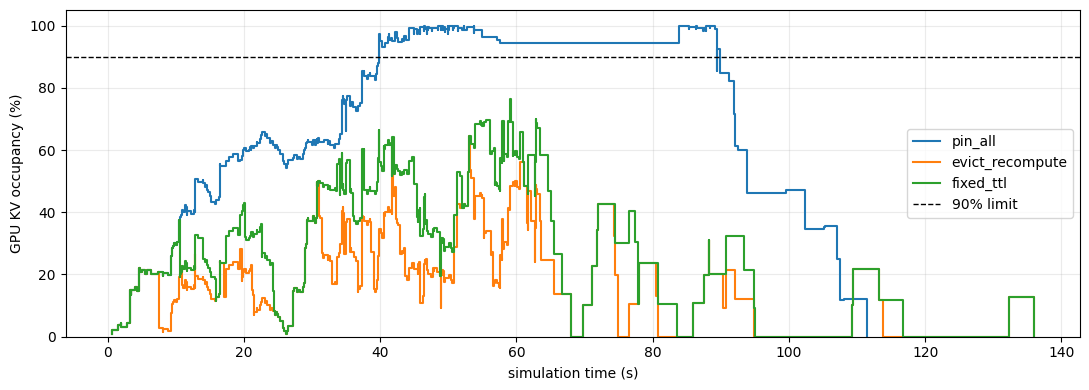

In [46]:
fig, ax = plt.subplots(figsize=(11, 4))
for policy in WEEK7_POLICIES:
    run_id = f'w1_s4_seed0__{policy}'
    occ = pd.read_csv(OUTPUT / 'runs' / run_id / 'occupancy.csv')
    occupancy_pct = occ.used_blocks / occ.total_blocks * 100
    ax.step(occ.time_ms / 1000, occupancy_pct, where='post', label=policy)
ax.axhline(90, color='black', linestyle='--', linewidth=1, label='90% limit')
ax.set(xlabel='simulation time (s)', ylabel='GPU KV occupancy (%)', ylim=(0, 105))
ax.grid(alpha=.25)
ax.legend()
plt.tight_layout()

## 15. 해석할 때 확인할 점

- `comparison.csv`의 값은 seed 5개의 평균과 표준편차입니다.
- TTFT SLO는 정책별 동일 seed W0를 기준으로 3배 이하인지 판정합니다.
- 거절률은 10% 이하, Peak KV 점유율은 90% 이하를 통과로 봅니다.
- `all_seeds_pass`는 모든 seed가 세 기준을 전부 통과해야 True입니다.
- Evict/Recompute와 Fixed TTL은 점유율을 줄이는 대신 재계산 토큰이 늘 수 있으므로 보조 지표도 함께 해석합니다.
- 시스템 처리 속도를 실측값으로 교체하기 전에는 절대 성능 수치로 주장하지 않습니다.